### Датасет: сделки с недвижимостью Москвы, 2015–2026


### Датасет содержит следующие колонки:

- `region` — административный округ Москвы.
- `district` — район расположения объекта.
- `street` — улица.
- `wall_material_code` — код материала стен; используется как категориальный признак, а не количественное число.
- `year_build` — год постройки дома.
- `floor` — этаж квартиры.
- `area` — общая площадь квартиры в квадратных метрах.
- `period_start_date` — дата начала периода наблюдения/сделки.
- `price` — цена объекта в рублях. Это целевой признак для задачи регрессии.

В работе применяются обязательные фильтры: `area > 25` и `price > 7_000_000`. Фильтры строгие: площадь ровно 25 м² и цена ровно 7 000 000 рублей не проходят.



python -m venv .venv

.venv\Scripts\activate.bat

python -m pip install pandas numpy matplotlib seaborn scikit-learn scipy jupyter ipykernel

jupyter notebook

#### Загрузка данных и первичный анализ

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from scipy.stats import pearsonr
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)


In [2]:
from pathlib import Path

DATA_PATH = Path("СДЕЛКИ_Мос_2015-2026.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Файл не найден. Ищу здесь: {DATA_PATH.resolve()}"
    )

print("CSV найден:", DATA_PATH.resolve())

CSV найден: C:\Users\AnnaA\Desktop\Система прогнозирования\СДЕЛКИ_Мос_2015-2026.csv


In [3]:
try:
    # Явно указываем разделитель столбцов ';'
    df = pd.read_csv(DATA_PATH, sep=';', encoding='utf-8-sig')
except UnicodeDecodeError:
    # Если кодировка utf-8-sig не подошла, пробуем cp1251 с тем же разделителем
    df = pd.read_csv(DATA_PATH, sep=';', encoding='cp1251')

# Нормализуем пробелы в названиях колонок
df.columns = df.columns.astype(str).str.strip().str.lower()

print(f"Размер датасета: {df.shape[0]} строк и {df.shape[1]} колонок")
print("\nПервые строки датасета:")
display(df.head())
print("\nИнформация о типах данных:")
df.info()

expected_cols = ['region', 'district', 'street', 'wall_material_code',
                 'year_build', 'floor', 'area', 'period_start_date', 'price']
missing_cols = [c for c in expected_cols if c not in df.columns]
if missing_cols:
    raise ValueError(f"Не найдены столбцы {missing_cols}. Фактические столбцы: {df.columns.tolist()}")

Размер датасета: 57431 строк и 9 колонок

Первые строки датасета:


,region,district,street,wall_material_code,year_build,floor,area,period_start_date,price
0,САО,Бескудниковский,Дмитровское,61001007004,1966.0,12,"64,2",01.01.2024,18981000
1,САО,Головинский,Кронштадтский,61001007001,1974.0,7,"63,1",01.01.2024,14700000
2,САО,Левобережный,Ленинградское,61001006001,2007.0,2,"93,8",01.01.2024,29500000
3,САО,Беговой,Расковой,61001007004,1963.0,3,"44,7",01.01.2024,15500000
4,САО,Западное Дегунино,Маршала Федоренко,61001007001,1981.0,3,"45,6",01.01.2024,8074150



Информация о типах данных:
<class 'pandas.DataFrame'>
RangeIndex: 57431 entries, 0 to 57430
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   region              57431 non-null  str    
 1   district            57431 non-null  str    
 2   street              57431 non-null  str    
 3   wall_material_code  57431 non-null  int64  
 4   year_build          57396 non-null  float64
 5   floor               57431 non-null  int64  
 6   area                57431 non-null  str    
 7   period_start_date   57431 non-null  str    
 8   price               57431 non-null  str    
dtypes: float64(1), int64(2), str(6)
memory usage: 3.9 MB


#### Очистка данных
- удаление дубликатов
- преобразование числовых значений, в том числе площади с десятичной запятой
- преобразование даты
- удаление строк с пропусками в обязательных полях
- удаление физически невозможных значений
- фильтрация: площадь строго больше 25 м² и цена строго больше 7 000 000 рублей


In [4]:
# Сохраняем исходное количество строк
start_len = len(df)

# Удаляем полные дубликаты
df = df.drop_duplicates().copy()
print(f"Удалено дубликатов: {start_len - len(df)}")

# Текстовые и кодовые поля приводим к строковому типу; код материала — категория
text_cols = ['region', 'district', 'street', 'wall_material_code']
for col in text_cols:
    df[col] = df[col].astype('string').str.strip()
    df[col] = df[col].replace({'': pd.NA, 'nan': pd.NA, 'None': pd.NA})

# Преобразуем числа, включая площадь с десятичной запятой
def clean_numeric(series):
    values = (series.astype('string')
              .str.replace('\u00a0', '', regex=False)
              .str.replace(' ', '', regex=False)
              .str.replace(',', '.', regex=False))
    return pd.to_numeric(values, errors='coerce')

for col in ['year_build', 'floor', 'area', 'price']:
    df[col] = clean_numeric(df[col])

df['period_start_date'] = pd.to_datetime(df['period_start_date'], errors='coerce', dayfirst=True)

# Удаляем записи без обязательных числовых полей
df = df.dropna(subset=['year_build', 'floor', 'area', 'price']).copy()

# Исключаем невозможные значения, но не удаляем высокую цену как выброс автоматически:
# дорогие объекты могут быть реальными, а порог цены задан отдельно в задании.
current_year = pd.Timestamp.today().year
df = df[(df['price'] > 0) & (df['area'] > 0) & (df['floor'] >= 1) &
        (df['year_build'].between(1800, current_year + 5))].copy()

df['year_build'] = df['year_build'].astype(int)
df['floor'] = df['floor'].astype(int)
df['price'] = df['price'].round().astype('int64')

print(f"Осталось после базовой очистки: {len(df)} строк")
print("Пропуски по столбцам:")
display(df.isna().sum().to_frame('missing_count'))

# Строгие фильтры из задания
rows_before_filter = len(df)
df = df[(df['area'] > 25) & (df['price'] > 7_000_000)].copy().reset_index(drop=True)
print(f"Удалено фильтрами area > 25 и price > 7 000 000: {rows_before_filter - len(df)}")
print(f"Осталось строк: {len(df)}")

assert (df['area'] > 25).all(), 'Найдена площадь <= 25'
assert (df['price'] > 7_000_000).all(), 'Найдена цена <= 7 000 000'

# Минимум для оси цены: не обрезаем графики произвольным значением
MIN_PRICE_ON_GRAPH = None


Удалено дубликатов: 674
Осталось после базовой очистки: 56722 строк
Пропуски по столбцам:


,missing_count
region,0
district,0
street,0
wall_material_code,0
year_build,0
floor,0
area,0
period_start_date,0
price,0


Удалено фильтрами area > 25 и price > 7 000 000: 8782
Осталось строк: 47940


Я буду выполнять задачу множественной регрессии:

Предсказать цену квартиры (`price`, рубли) по характеристикам `region`, `district`, `street`, `wall_material_code`, `year_build`, `floor`, `area` и признакам, извлечённым из `period_start_date`.

В отличие от исходного примера, здесь нет площади кухни и расстояния до метро/центра, поэтому эти признаки не используются.


### Разведочный анализ данных (EDA)

## Цена квартиры в зависимости от материала стен

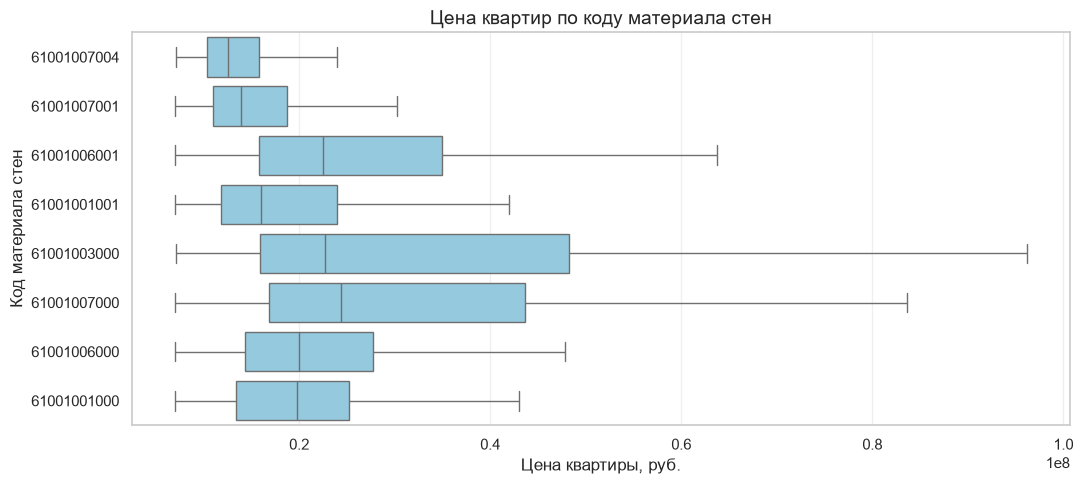

,median_price_rub
wall_material_code,
61001007004,12500000.0
61001007001,13900000.0
61001001001,16000000.0
61001001000,19778962.0
61001006000,20000000.0
61001006001,22525053.0
61001003000,22700000.0
61001007000,24361730.0


In [5]:
# Сравниваем цену по коду материала стен
plot_df = df.dropna(subset=['wall_material_code', 'price']).copy()
median_prices = plot_df.groupby('wall_material_code')['price'].median().sort_values()

if not median_prices.empty:
    plt.figure(figsize=(11, max(5, 0.35 * len(median_prices))))
    ax = sns.boxplot(data=plot_df, y='wall_material_code', x='price', color='skyblue', showfliers=False)
    plt.title('Цена квартир по коду материала стен', fontsize=14)
    plt.xlabel('Цена квартиры, руб.')
    plt.ylabel('Код материала стен')
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()
    display(median_prices.rename('median_price_rub').to_frame())
else:
    print('Нет данных для графика по материалу стен.')


На графике можно сравнить распределение цен по кодам материала стен. Разницу и её величину нужно интерпретировать по фактическому графику после запуска; заранее заданные проценты не используются.

### Цена квартиры в зависимости от района

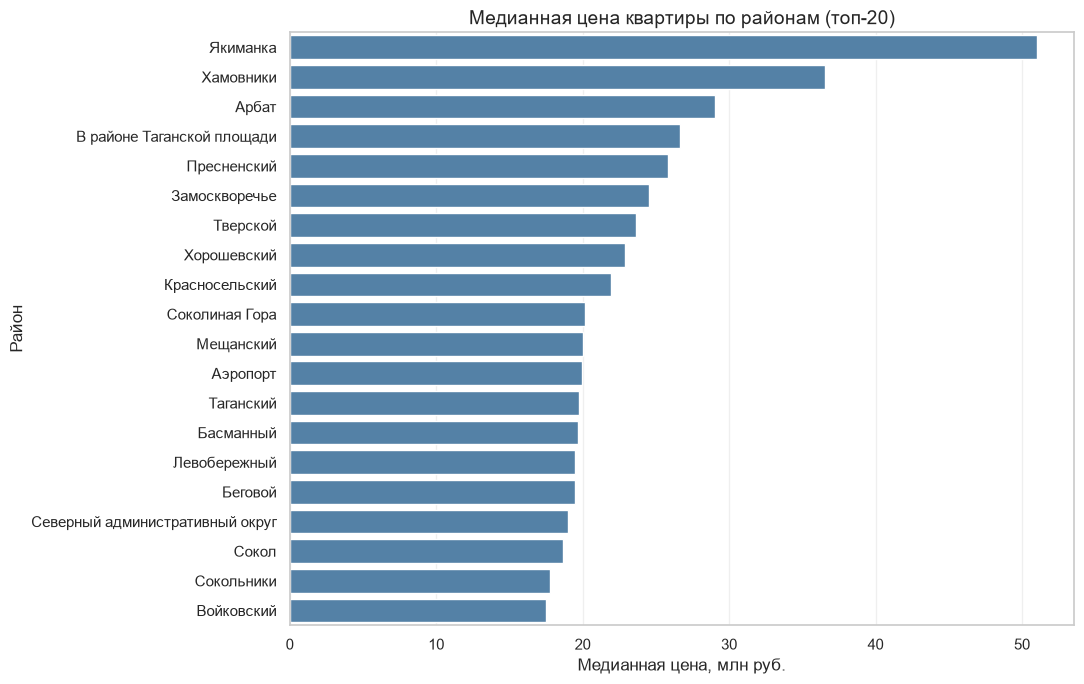

,median_price_mln_rub,object_count
district,,
Якиманка,51.00,660
Хамовники,36.55,1000
Арбат,29.03,320
В районе Таганской площади,26.65,2
Пресненский,25.80,2354
Замоскворечье,24.53,543
Тверской,23.61,906
Хорошевский,22.90,2968
Красносельский,21.95,506


In [6]:
# Медианная цена по районам (в млн рублей)
plot_df = df.dropna(subset=['district', 'price']).copy()

stats = (
    plot_df.groupby('district')['price']
    .agg(['median', 'count'])
    .sort_values('median', ascending=False)
    .head(20)
)

# Переводим медианную цену из рублей в млн рублей
stats['median'] = stats['median'] / 1_000_000

plt.figure(figsize=(11, max(5, 0.35 * len(stats))))

ax = sns.barplot(
    x=stats['median'].values,
    y=stats.index.astype(str),
    color='steelblue'
)

plt.title('Медианная цена квартиры по районам (топ-20)', fontsize=14)
plt.xlabel('Медианная цена, млн руб.')
plt.ylabel('Район')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

display(
    stats.rename(columns={
        'median': 'median_price_mln_rub',
        'count': 'object_count'
    }).round({'median_price_mln_rub': 2})
)

На графике показана медианная цена по районам. Вывод о том, какие районы дороже, делается по результатам фактического расчёта на загруженном датасете.

Далее посмотрим, как площадь квартиры связана со стоимостью.

### Цена квартиры в зависимости от площади

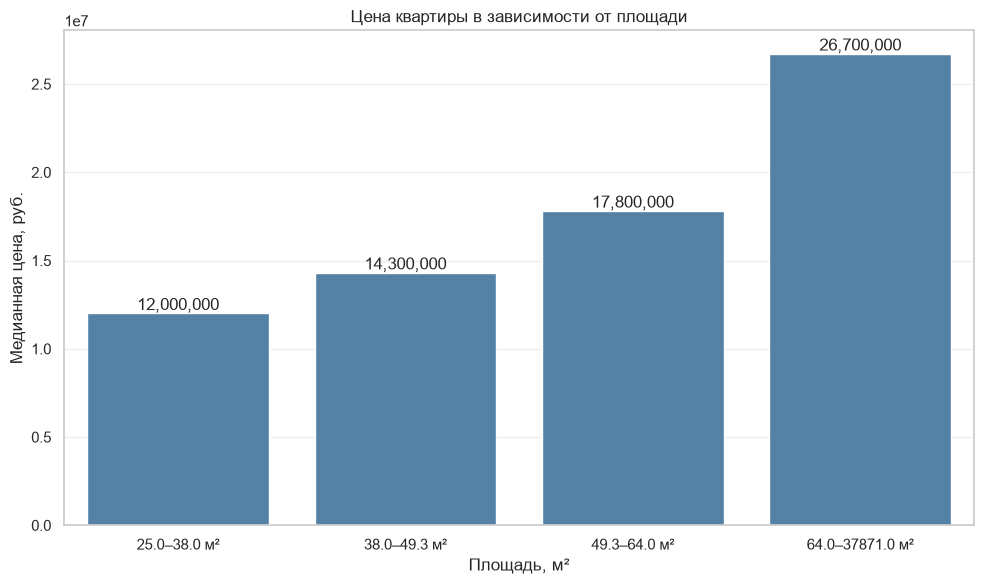

In [7]:
# Делим площадь на группы по квартилям
plot_df = df.dropna(subset=['area', 'price']).copy()
if plot_df['area'].nunique() >= 2:
    plot_df['area_category'] = pd.qcut(plot_df['area'], q=4, duplicates='drop')
    stats = plot_df.groupby('area_category', observed=True)['price'].median()
    x_labels = [f'{interval.left:.1f}–{interval.right:.1f} м²' for interval in stats.index]

    plt.figure(figsize=(10, 6))
    ax = sns.barplot(x=x_labels, y=stats.values, color='steelblue')
    plt.title('Цена квартиры в зависимости от площади')
    plt.xlabel('Площадь, м²')
    plt.ylabel('Медианная цена, руб.')
    plt.grid(axis='y', alpha=0.3)
    for i, value in enumerate(stats.values):
        ax.text(i, value, f'{value:,.0f}', ha='center', va='bottom')
    plt.tight_layout()
    plt.show()
else:
    print('Недостаточно различных значений площади для построения групп.')


Сравнение медианной цены по группам площади позволяет оценить связь площади и стоимости. Конкретные выводы делаются после построения графика.

### Стоимость квартир в зависимости от этажа

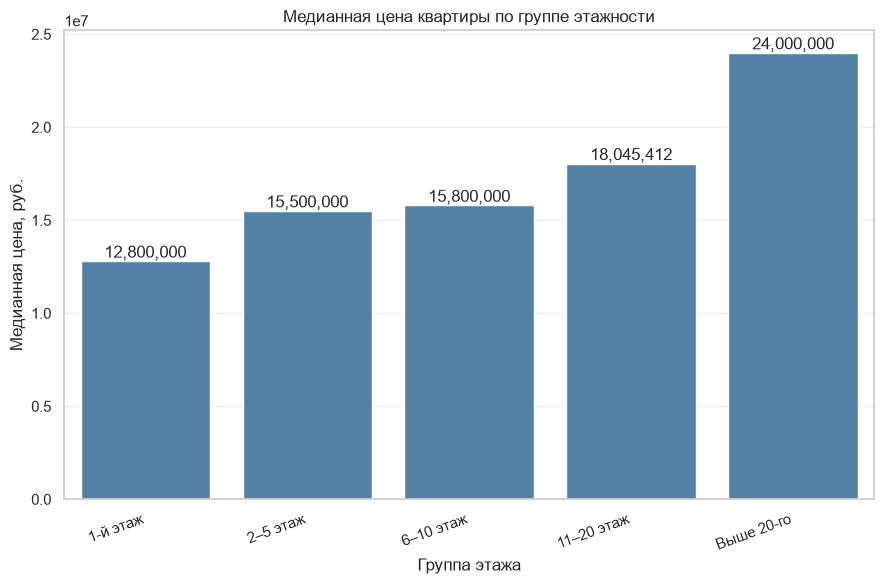

In [8]:
# Здесь floor — фактический номер этажа, а не бинарный признак.
plot_df = df.dropna(subset=['floor', 'price']).copy()
plot_df['floor_group'] = pd.cut(
    plot_df['floor'], bins=[0, 1, 5, 10, 20, np.inf],
    labels=['1-й этаж', '2–5 этаж', '6–10 этаж', '11–20 этаж', 'Выше 20-го'],
    include_lowest=True
)
stats = plot_df.groupby('floor_group', observed=True)['price'].median()

if not stats.empty:
    plt.figure(figsize=(9, 6))
    ax = sns.barplot(x=stats.index.astype(str), y=stats.values, color='steelblue')
    plt.title('Медианная цена квартиры по группе этажности')
    plt.xlabel('Группа этажа')
    plt.ylabel('Медианная цена, руб.')
    plt.xticks(rotation=20, ha='right')
    plt.grid(axis='y', alpha=0.3)
    for i, value in enumerate(stats.values):
        ax.text(i, value, f'{value:,.0f}', ha='center', va='bottom')
    plt.tight_layout()
    plt.show()
else:
    print('Нет данных для анализа этажа.')


График сравнивает медианную цену объектов по этажам. Различия не следует заранее задавать фиксированными процентами: они рассчитываются по фактическим данным.

### Корреляционный анализ

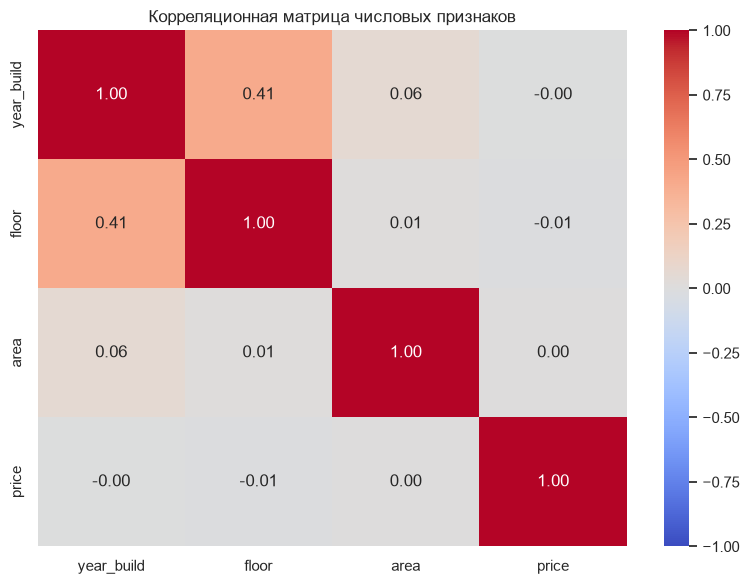

Корреляция признаков с целевой переменной price:
price         1.000
area          0.004
year_build   -0.001
floor        -0.013
Name: price, dtype: float64


In [9]:
# Для корреляции используем числовые признаки и целевую переменную
numeric_cols = ['year_build', 'floor', 'area', 'price']
df_corr = df[numeric_cols].copy()
corr_matrix = df_corr.corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Корреляционная матрица числовых признаков')
plt.tight_layout()
plt.show()

print('Корреляция признаков с целевой переменной price:')
print(corr_matrix['price'].sort_values(ascending=False).round(3))


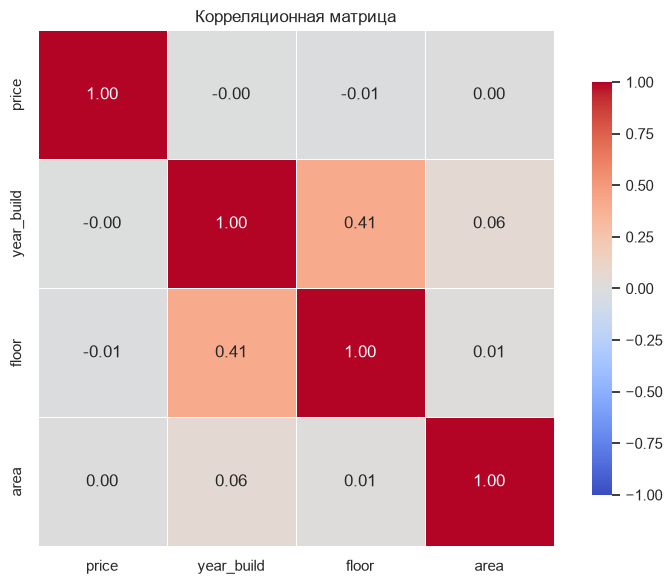

In [10]:
numeric_cols = ['price', 'year_build', 'floor', 'area']
corr_matrix = df[numeric_cols].corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5,
            vmin=-1, vmax=1, square=True, cbar_kws={'shrink': 0.8})
plt.title('Корреляционная матрица')
plt.tight_layout()
plt.show()


### Масштабирование признаков

Числовые признаки масштабируются для моделей, чувствительных к масштабу. Категориальные признаки кодируются отдельно с помощью one-hot encoding.

In [11]:
# Готовим признаки для моделей: дата раскладывается на год и месяц
model_df = df.copy()
model_df['period_year'] = model_df['period_start_date'].dt.year
model_df['period_month'] = model_df['period_start_date'].dt.month

categorical_cols = ['region', 'district', 'street', 'wall_material_code']
numeric_cols = ['year_build', 'floor', 'area', 'period_year', 'period_month']
feature_cols = categorical_cols + numeric_cols

# One-hot encoding для категорий; числовые признаки масштабируем MinMaxScaler.
# get_dummies позволяет сохранить понятную таблицу признаков для дальнейших ячеек.
X_all = pd.get_dummies(model_df[feature_cols], columns=categorical_cols, dummy_na=True, dtype=float)
X_all = X_all.replace([np.inf, -np.inf], np.nan)

# Заполняем пропуски числовых признаков медианой, чтобы масштабирование не падало.
for col in X_all.columns:
    if X_all[col].isna().any():
        X_all[col] = X_all[col].fillna(X_all[col].median() if X_all[col].notna().any() else 0)

scale_cols = X_all.columns.tolist()
sc1 = MinMaxScaler()
sc1_data = sc1.fit_transform(X_all)
X_scaled = pd.DataFrame(sc1_data, columns=[col + '_scaled' for col in scale_cols], index=model_df.index)

# Сохраняем цель и признаки в единой таблице для последующего разбиения.
model_data = X_scaled.copy()
model_data['price'] = model_df['price'].astype(float).values
print('Масштабирование и кодирование выполнены.')
print('Количество признаков после кодирования:', len(scale_cols))
display(model_data.head())


Масштабирование и кодирование выполнены.
Количество признаков после кодирования: 1163


,year_build_scaled,floor_scaled,area_scaled,period_year_scaled,period_month_scaled,region_ВАО_scaled,region_САО_scaled,region_ЦАО_scaled,region_<NA>_scaled,district_Арбат_scaled,district_Аэропорт_scaled,district_Басманный_scaled,district_Беговой_scaled,district_Бескудниковский_scaled,district_Богородское_scaled,district_В районе Таганской площади_scaled,district_Вешняки_scaled,district_Войковский_scaled,district_Восточное Дегунино_scaled,district_Восточное Измайлово_scaled,district_Восточный_scaled,district_Головинский_scaled,district_Гольяново_scaled,district_Дмитровский_scaled,district_Замоскворечье_scaled,district_Западное Дегунино_scaled,district_Ивановское_scaled,district_Измайлово_scaled,district_Коптево_scaled,district_Косино-Ухтомский_scaled,district_Красносельский_scaled,district_Левобережный_scaled,district_Метрогородок_scaled,district_Мещанский_scaled,district_Молжаниновский_scaled,district_Новогиреево_scaled,district_Новокосино_scaled,district_Перово_scaled,district_Преображенское_scaled,district_Пресненский_scaled,district_Савеловский_scaled,district_Северное Измайлово_scaled,district_Северный административный округ_scaled,district_Сокол_scaled,district_Соколиная Гора_scaled,district_Соколиная гора_scaled,district_Сокольники_scaled,district_Таганский_scaled,district_Тверской_scaled,district_Тимирязевский_scaled,district_Хамовники_scaled,district_Ховрино_scaled,district_Хорошевский_scaled,district_Якиманка_scaled,district_<NA>_scaled,street_1-й Амбулаторный_scaled,street_1-й Басманный_scaled,street_1-й Боткинский_scaled,street_1-й Войковский_scaled,street_1-й Волконский_scaled,street_1-й Вражский_scaled,street_1-й Голутвинский_scaled,street_1-й Зачатьевский_scaled,street_1-й Зборовский_scaled,street_1-й Колобовский_scaled,street_1-й Коптельский_scaled,street_1-й Красногвардейский_scaled,street_1-й Красносельский_scaled,street_1-й Лихачёвский_scaled,street_1-й Магистральный_scaled,street_1-й Неопалимовский_scaled,street_1-й Нижнелихоборский_scaled,street_1-й Николощеповский_scaled,street_1-й Новокузнецкий_scaled,street_1-й Новомихалковский_scaled,street_1-й Новоподмосковный_scaled,street_1-й Обыденский_scaled,street_1-й Самотёчный_scaled,street_1-й Смоленский_scaled,street_1-й Спасоналивковский_scaled,street_1-й Тружеников_scaled,street_1-й Хуторской_scaled,street_1-й Щипковский_scaled,street_1-й Электрозаводский_scaled,street_1-я 8 Марта_scaled,street_1-я Аэропортовская_scaled,street_1-я Бебеля_scaled,street_1-я Бухвостова_scaled,street_1-я Владимирская_scaled,street_1-я Гражданская_scaled,street_1-я Дубровская_scaled,street_1-я Квесисская_scaled,street_1-я Миусская_scaled,street_1-я Мясниковская_scaled,street_1-я Парковая_scaled,street_1-я Прядильная_scaled,street_1-я Радиаторская_scaled,street_1-я Тверская-Ямская_scaled,street_1-я Фрунзенская_scaled,street_1-я Хуторская_scaled,street_10-я Парковая_scaled,street_10-я Соколиной Горы_scaled,street_11-я Парковая_scaled,street_13-я Парковая_scaled,street_15-я Парковая_scaled,street_16-я Парковая_scaled,street_1905 Года_scaled,street_1905 года_scaled,street_2-й Балтийский_scaled,street_2-й Войковский_scaled,street_2-й Волконский_scaled,street_2-й Вражский_scaled,street_2-й Зачатьевский_scaled,street_2-й Кадашевский_scaled,street_2-й Казачий_scaled,street_2-й Котельнический_scaled,street_2-й Красногвардейский_scaled,street_2-й Красносельский_scaled,street_2-й Крестовский_scaled,street_2-й Лесной_scaled,street_2-й Лихачёвский_scaled,street_2-й Монетчиковский_scaled,street_2-й Новоподмосковный_scaled,street_2-й Обыденский_scaled,street_2-й Полевой_scaled,street_2-й Самотёчный_scaled,street_2-й Спасоналивковский_scaled,street_2-й Сыромятнический_scaled,street_2-й Хвостов_scaled,street_2-й Хорошёвский_scaled,street_2-й Щемиловский_scaled,street_2-й Щипковский_scaled,street_2-я Брестская_scaled,street_2-я Бухвостова_scaled,street_2-я Владимирская_scaled,street_2-я Дубровская_scaled,street_2-я Звенигородская_scaled,street_2-я Квесисская_scaled,street_2-я Миусская_scaled,stree

Выбор метрик для оценки качества регрессии
MAE — средняя абсолютная ошибка (в тыс. долларов)

MSE — средняя квадратичная ошибка

R² — коэффициент детерминации

Класс для сохранения и визуализации метрик

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


class MetricLogger:

    def __init__(self):
        self._data = {}
        self._df_cache = None

    def add(self, metric, category, value):
        self._data[(metric, category)] = float(value)
        self._df_cache = None  # сбрасываем кэш при изменении данных

    @property
    def df(self):
        """DataFrame (metric, alg, value) для совместимости со старым кодом."""
        if self._df_cache is None:
            records = [{'metric': m, 'alg': cat, 'value': val}
                       for (m, cat), val in self._data.items()]
            self._df_cache = pd.DataFrame(records, columns=['metric', 'alg', 'value'])
        return self._df_cache

    def get_data_for_metric(self, metric, ascending=True):
        """Отсортированные массивы категорий и значений для заданной метрики."""
        filtered = {cat: val for (m, cat), val in self._data.items() if m == metric}

        if not filtered:
            return np.array([], dtype=object), np.array([])

        sorted_items = sorted(filtered.items(), key=lambda item: item[1],
                              reverse=not ascending)

        categories, values = zip(*sorted_items)
        return np.array(categories, dtype=object), np.array(values)

    def table(self, metrics=('MAE', 'MSE', 'R2')):
        """Сводная таблица: алгоритмы по строкам, метрики по столбцам."""
        pivot = self.df.pivot(index='alg', columns='metric', values='value')
        cols = [m for m in metrics if m in pivot.columns]
        return pivot[cols].sort_values(by=cols[-1], ascending=False).round(3)

    def plot(self, str_header, metric, ascending=True, figsize=(7, 6)):
        """Горизонтальная столбчатая диаграмма для заданной метрики."""
        array_labels, array_metric = self.get_data_for_metric(metric, ascending)

        if len(array_metric) == 0:
            print(f'Нет значений для метрики {metric}')
            return

        fig, ax1 = plt.subplots(figsize=figsize)
        pos = np.arange(len(array_metric))
        ax1.barh(pos, array_metric, align='center', height=0.5, tick_label=array_labels)
        ax1.set_title(str_header)
        ax1.set_xlabel(metric)

        for a, b in zip(pos, array_metric):
            ax1.text(0.5, a - 0.05, f'{b:.3f}', color='white')

        plt.tight_layout()
        plt.show()

### Формирование обучающей и тестовой выборок

In [13]:
# Разделяем данные на train (80%) и test (20%)
if len(model_data) < 10:
    print(f'После фильтрации осталось {len(model_data)} объектов. Для обучения и оценки моделей желательно не менее 10; проверьте объём данных.')

train_data, test_data = train_test_split(model_data, test_size=0.2, random_state=42)
regr_cols_scaled = [col for col in model_data.columns if col != 'price']

regr_X_train = train_data[regr_cols_scaled]
regr_X_test = test_data[regr_cols_scaled]
regr_Y_train = train_data['price']
regr_Y_test = test_data['price']

print('Размеры выборок:')
print('X_train:', regr_X_train.shape, 'y_train:', regr_Y_train.shape)
print('X_test :', regr_X_test.shape, 'y_test :', regr_Y_test.shape)


Размеры выборок:
X_train: (38352, 1163) y_train: (38352,)
X_test : (9588, 1163) y_test : (9588,)


### Построение базового решения (baseline)

In [14]:
import time

# Сравниваем несколько регрессионных моделей на одинаковых данных.
# SVR отключён по умолчанию: на выборке ~38k x 1163 он обучается часы (сложность ~O(n^2)),
# при этом показывает одни из худших метрик. Включите флаг, если он нужен.
RUN_SVR = False

regr_models = {
    'LR': LinearRegression(),
    'KNN_5': KNeighborsRegressor(n_neighbors=min(5, max(1, len(regr_X_train)))),
    'Tree': DecisionTreeRegressor(random_state=42),
    'RF': RandomForestRegressor(random_state=42, n_estimators=100, n_jobs=-1),
    'GB': GradientBoostingRegressor(random_state=42, n_estimators=100)
}
if RUN_SVR:
    regr_models['SVR'] = SVR()

regrMetricLogger = MetricLogger()

def regr_train_model(model_name, model, logger):
    t0 = time.time()
    model.fit(regr_X_train, regr_Y_train)
    y_pred = model.predict(regr_X_test)
    mae = mean_absolute_error(regr_Y_test, y_pred)
    mse = mean_squared_error(regr_Y_test, y_pred)
    r2 = r2_score(regr_Y_test, y_pred) if len(regr_Y_test) >= 2 else np.nan
    logger.add('MAE', model_name, mae)
    logger.add('MSE', model_name, mse)
    logger.add('R2', model_name, r2)
    elapsed = time.time() - t0
    print(f'{model_name:12} MAE={mae:,.2f} руб.  MSE={mse:,.2f}  R2={r2:.3f}  (обучение+предсказание: {elapsed:.1f} c)')

print('Сравнение моделей без подбора гиперпараметров')
for name, model in regr_models.items():
    regr_train_model(name, model, regrMetricLogger)


Сравнение моделей без подбора гиперпараметров
LR           MAE=59,847,481.81 руб.  MSE=183,144,934,866,943,264.00  R2=-0.288  (обучение+предсказание: 12.3 c)
KNN_5        MAE=28,225,354.39 руб.  MSE=937,592,068,545,003,392.00  R2=-5.592  (обучение+предсказание: 17.5 c)
Tree         MAE=34,892,626.41 руб.  MSE=2,024,359,165,861,986,048.00  R2=-13.232  (обучение+предсказание: 6.6 c)
RF           MAE=28,881,430.23 руб.  MSE=1,465,488,131,122,795,520.00  R2=-9.303  (обучение+предсказание: 91.1 c)
GB           MAE=32,848,319.43 руб.  MSE=1,802,222,939,847,311,104.00  R2=-11.671  (обучение+предсказание: 84.4 c)


### Исследование важности признаков

Лучшие параметры дерева: {'max_depth': 3}

Метрики после настройки:
MAE: 36053904.01058574
R2 : -7.4095093628802235


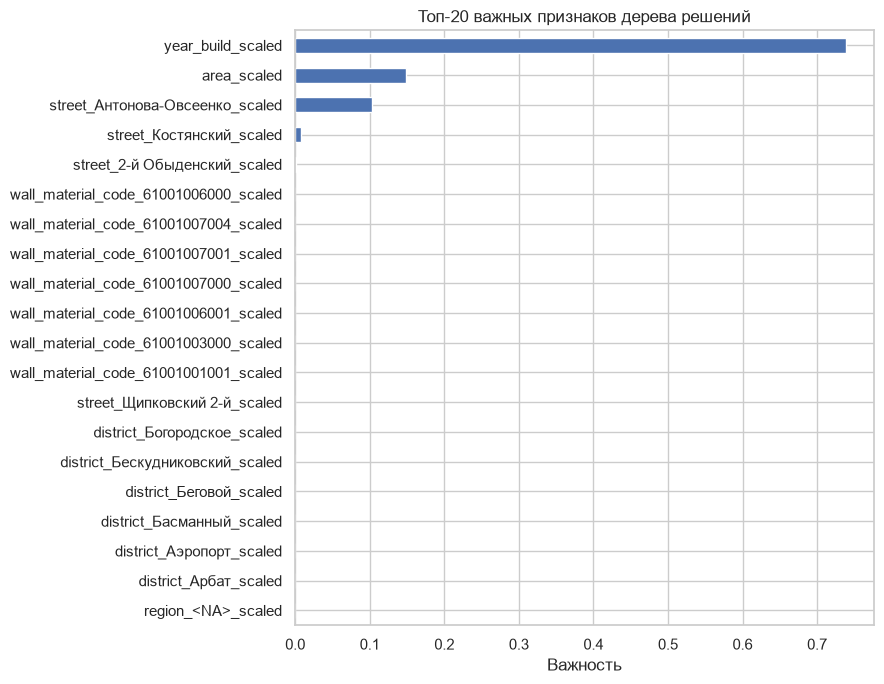

In [ ]:
# Подбираем максимальную глубину дерева решений.
# Число фолдов ограничиваем размером обучающей выборки.
cv_splits = min(5, len(regr_X_train))
if cv_splits >= 2:
    params = {'max_depth': [3, 5, 7, 10, None]}
    grid_tree = GridSearchCV(
        DecisionTreeRegressor(random_state=42), params,
        cv=cv_splits, scoring='r2', n_jobs=-1
    )
    grid_tree.fit(regr_X_train, regr_Y_train)
    print('Лучшие параметры дерева:', grid_tree.best_params_)

    tuned_tree = DecisionTreeRegressor(
        max_depth=grid_tree.best_params_['max_depth'], random_state=42
    )
    tuned_tree.fit(regr_X_train, regr_Y_train)
    pred_tuned = tuned_tree.predict(regr_X_test)
    print('\nМетрики после настройки:')
    print('MAE:', mean_absolute_error(regr_Y_test, pred_tuned))
    print('R2 :', r2_score(regr_Y_test, pred_tuned) if len(regr_Y_test) >= 2 else np.nan)

    importances = pd.Series(tuned_tree.feature_importances_, index=regr_X_train.columns).sort_values().tail(3)
    plt.figure(figsize=(9, 7))
    importances.plot(kind='barh')
    plt.title('Топ-20 важных признаков дерева решений')
    plt.xlabel('Важность')
    plt.tight_layout()
    plt.show()
else:
    print('Недостаточно объектов для GridSearchCV дерева решений.')


# Подбор гиперпараметра через GridSearchCV

In [16]:
# Подбор числа соседей K для KNN
# Перебор сокращён до K=1..5 (каждое значение K — это полноценный предсказатель,
# который на 38k строк считает расстояния до всех соседей — O(n^2)).
cv_splits = min(5, len(regr_X_train))
if cv_splits >= 2:
    max_k = min(5, len(regr_X_train))
    param_grid = {'n_neighbors': list(range(1, max_k + 1))}
    grid = GridSearchCV(
        KNeighborsRegressor(), param_grid,
        cv=KFold(n_splits=cv_splits, shuffle=True, random_state=42),
        scoring='neg_mean_absolute_error', n_jobs=-1
    )
    grid.fit(regr_X_train, regr_Y_train)
    print('Лучший параметр K:', grid.best_params_)
    print('Лучшее значение MAE на кросс-валидации, руб.:', -grid.best_score_)
else:
    grid = None
    print('Недостаточно строк для кросс-валидации KNN.')


Лучший параметр K: {'n_neighbors': 4}
Лучшее значение MAE на кросс-валидации, руб.: 26639264.35499946


GridSearchCV перебирает различные значения параметра K для K-ближайших соседей и выбирает вариант с лучшим средним MAE при кросс-валидации. Количество разбиений уменьшается, если обучающая выборка мала.

### Формирование выводов о качестве моделей

Метрики качества (MAE, MSE и R²) рассчитываются после обучения на реальном датасете. До запуска нельзя корректно указать лучшую модель или её значения метрик.

### Повторное обучение с лучшими параметрами

In [17]:
if grid is not None:
    best_k = grid.best_params_['n_neighbors']
    regr_models_grid = {
        'KNN_default_5': KNeighborsRegressor(n_neighbors=min(5, len(regr_X_train))),
        f'KNN_tuned_{best_k}': KNeighborsRegressor(n_neighbors=best_k)
    }
    print('Результаты после подбора гиперпараметров')
    for name, model in regr_models_grid.items():
        regr_train_model(name, model, regrMetricLogger)
else:
    print('Повторное обучение KNN пропущено.')


Результаты после подбора гиперпараметров
KNN_default_5 MAE=28,225,354.39 руб.  MSE=937,592,068,545,003,392.00  R2=-5.592  (обучение+предсказание: 15.6 c)
KNN_tuned_4  MAE=26,776,901.86 руб.  MSE=806,773,174,056,977,920.00  R2=-4.672  (обучение+предсказание: 17.6 c)


### Формирование выводов о качестве моделей

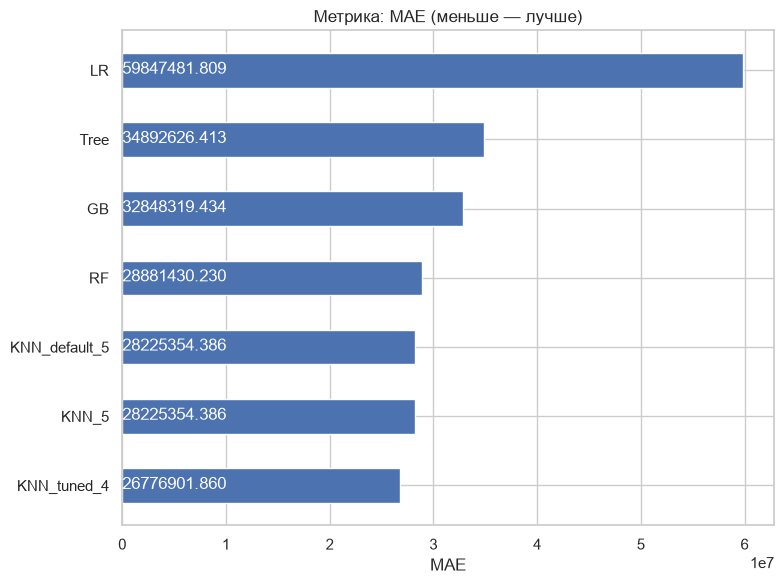

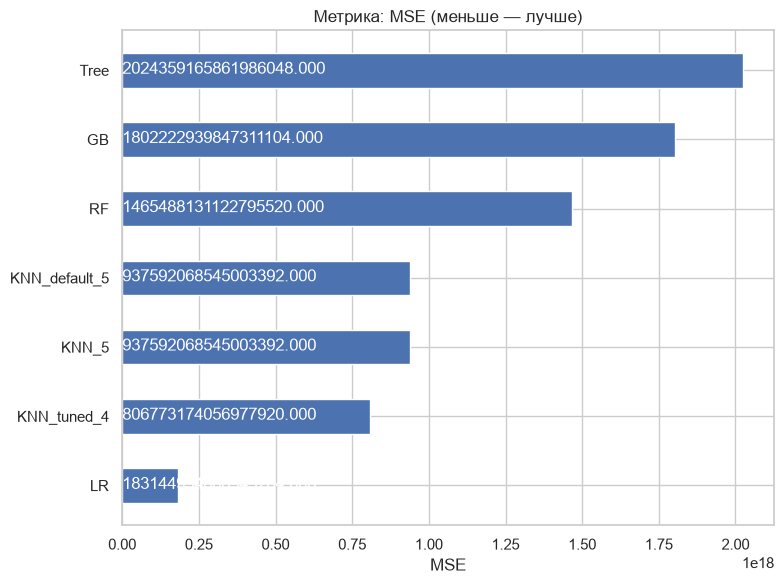

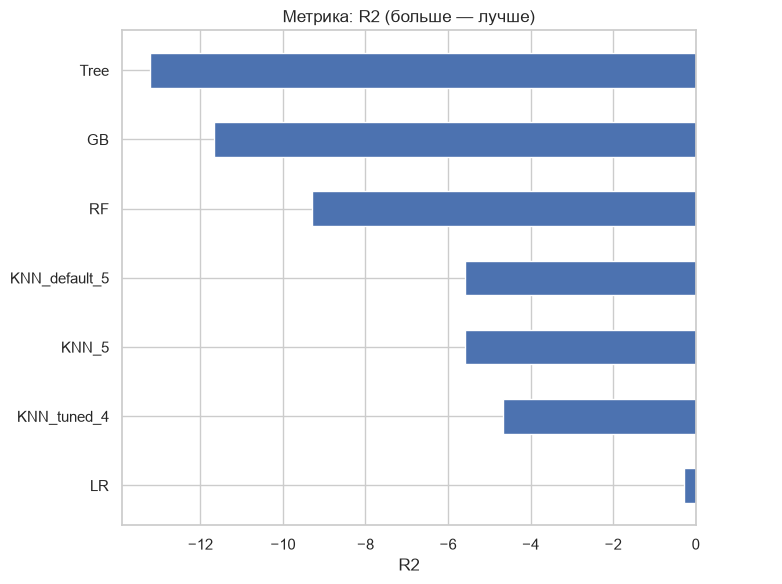


Итоговая таблица качества моделей:


metric,MAE,MSE,R2
alg,,,
LR,5.984748e+07,1.831449e+17,-0.288
KNN_tuned_4,2.677690e+07,8.067732e+17,-4.672
KNN_5,2.822535e+07,9.375921e+17,-5.592
KNN_default_5,2.822535e+07,9.375921e+17,-5.592
RF,2.888143e+07,1.465488e+18,-9.303
GB,3.284832e+07,1.802223e+18,-11.671
Tree,3.489263e+07,2.024359e+18,-13.232


In [18]:
# Графики и сводная таблица метрик
regrMetricLogger.plot('Метрика: MAE (меньше — лучше)', 'MAE', ascending=True, figsize=(8, 6))
regrMetricLogger.plot('Метрика: MSE (меньше — лучше)', 'MSE', ascending=True, figsize=(8, 6))
regrMetricLogger.plot('Метрика: R2 (больше — лучше)', 'R2', ascending=False, figsize=(8, 6))

print('\nИтоговая таблица качества моделей:')
display(regrMetricLogger.table())


### Анализ результатов

Сравните модели по таблице метрик после запуска. Для MAE и MSE меньшее значение лучше, для R² — как правило, большее. Метрики зависят от состава датасета, очистки и разбиения на выборки.

### Сравнение предсказанных и реальных цен

In [19]:
# Сводная таблица метрик берётся напрямую из логгера (fast dict-версия)
metrics_table = regrMetricLogger.table()
best_model_name = metrics_table['MAE'].idxmin()
best_model = regr_models.get(best_model_name)
if best_model is None and 'regr_models_grid' in globals():
    best_model = regr_models_grid.get(best_model_name)

if best_model is None:
    raise ValueError(f'Не удалось найти модель {best_model_name} среди обучавшихся моделей.')

best_model.fit(regr_X_train, regr_Y_train)
pred_test = best_model.predict(regr_X_test)
comparison = pd.DataFrame({
    'real_price_rub': regr_Y_test.to_numpy(),
    'predicted_price_rub': pred_test.round(0)
})
comparison['error_rub'] = comparison['real_price_rub'] - comparison['predicted_price_rub']
print('Сравнение предсказанных и реальных цен (первые 10 объектов):')
display(comparison.head(10))


Сравнение предсказанных и реальных цен (первые 10 объектов):


,real_price_rub,predicted_price_rub,error_rub
0,16120630.0,16467658.0,-347028.0
1,29872251.0,21965788.0,7906463.0
2,12901504.0,40770797.0,-27869293.0
3,7700000.0,10562500.0,-2862500.0
4,24905000.0,23020735.0,1884265.0
5,15000000.0,26575000.0,-11575000.0
6,35000000.0,27475000.0,7525000.0
7,23800000.0,18425000.0,5375000.0
8,16001815.0,20994426.0,-4992611.0
9,16500000.0,15812500.0,687500.0


### Наглядный пример работы прогнозирующей модели

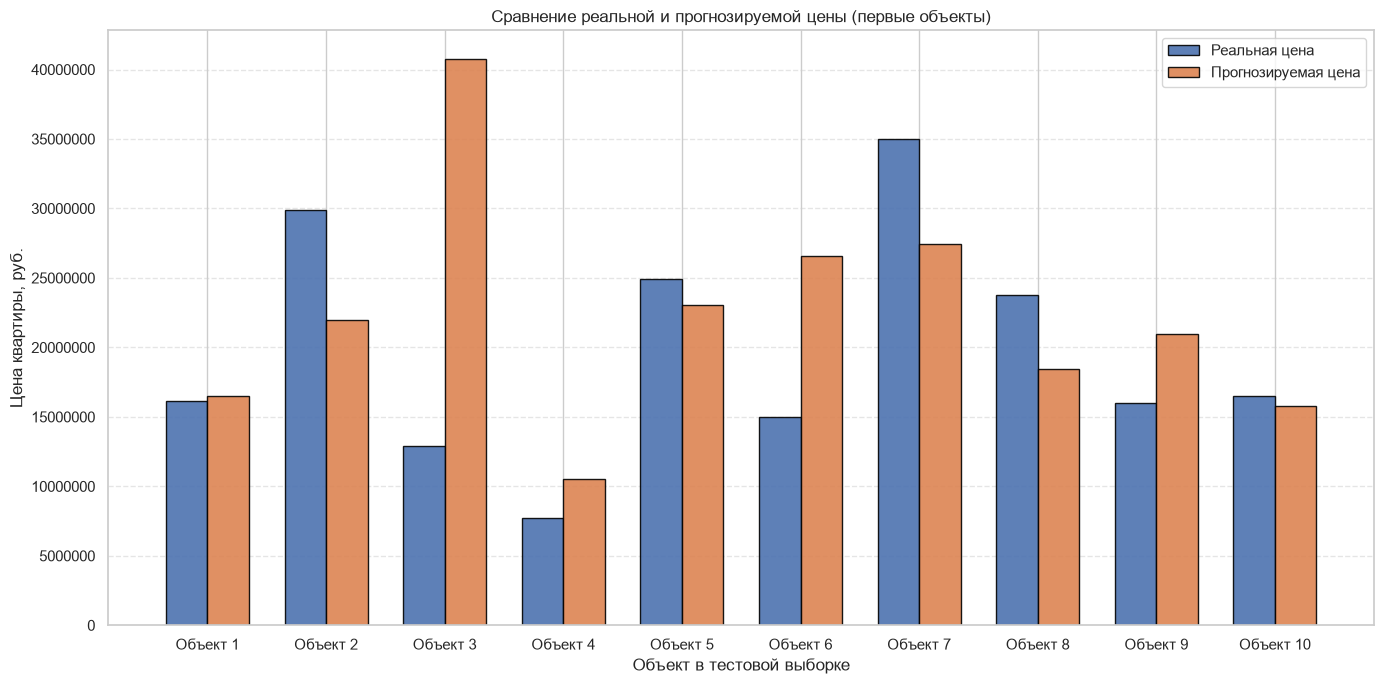

In [20]:
n = min(10, len(comparison))
sample = comparison.head(n).copy()

if n > 0:
    x = np.arange(n)
    width = 0.35
    plt.figure(figsize=(14, 7))
    plt.bar(x - width/2, sample['real_price_rub'], width, label='Реальная цена', alpha=0.9, edgecolor='black')
    plt.bar(x + width/2, sample['predicted_price_rub'], width, label='Прогнозируемая цена', alpha=0.9, edgecolor='black')
    plt.xlabel('Объект в тестовой выборке')
    plt.ylabel('Цена квартиры, руб.')
    plt.title('Сравнение реальной и прогнозируемой цены (первые объекты)')
    plt.xticks(x, [f'Объект {i+1}' for i in range(n)])
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.ticklabel_format(axis='y', style='plain')
    plt.tight_layout()
    plt.show()
else:
    print('Нет тестовых объектов для визуализации.')


### Диагностика качества лучшей модели
визуализация предсказаний и анализ ошибок на тестовой выборке


Используется лучшая модель по MAE: KNN_tuned_4


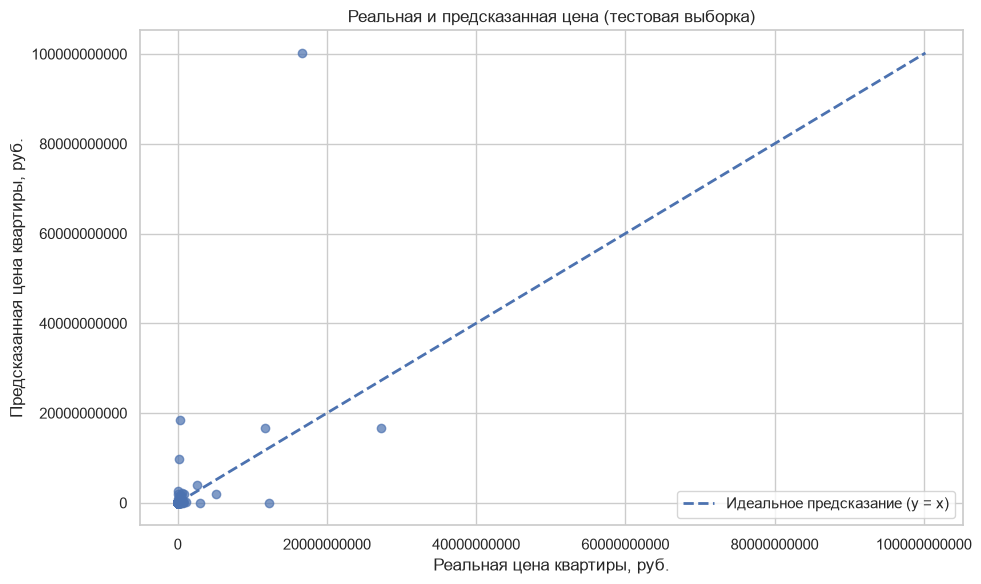

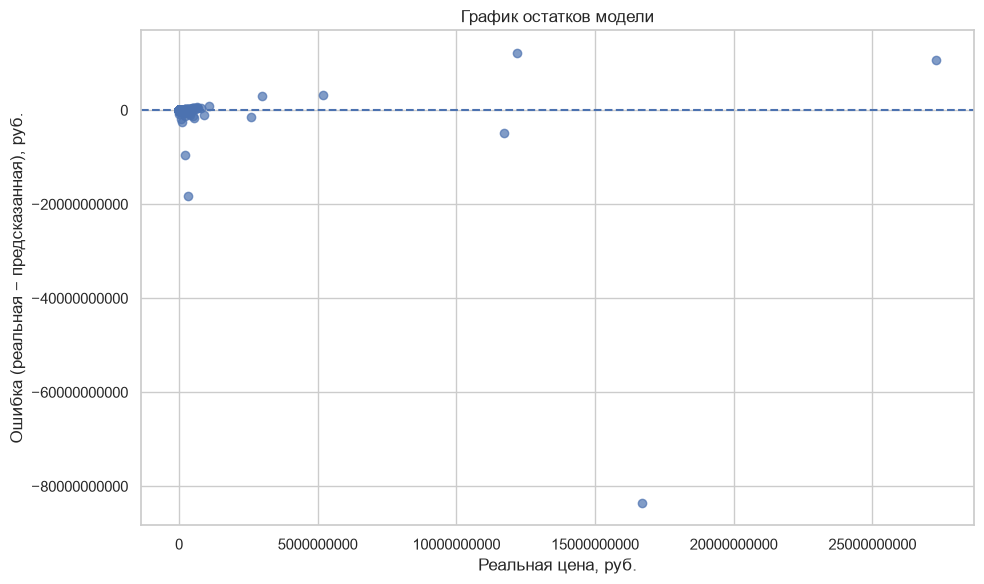


Статистика ошибок модели:
MAE = 26,776,901.86 руб.
Максимальная абсолютная ошибка = 83,519,994,000.00 руб.
Средняя ошибка = -11,151,762.38 руб.

Относительные показатели:
MAPE = 40.98%
Доля прогнозов с ошибкой < 10% = 23.7%
Доля прогнозов с ошибкой < 15% = 34.8%


In [21]:
# Сводная таблица метрик берётся напрямую из логгера (fast dict-версия)
metrics_table = regrMetricLogger.table()
best_model_name = metrics_table['MAE'].idxmin()
best_model = regr_models.get(best_model_name)
if best_model is None and 'regr_models_grid' in globals():
    best_model = regr_models_grid.get(best_model_name)

print(f'\nИспользуется лучшая модель по MAE: {best_model_name}')
best_model.fit(regr_X_train, regr_Y_train)
pred_test = best_model.predict(regr_X_test)
comparison = pd.DataFrame({
    'real_price': regr_Y_test.to_numpy(),
    'predicted_price': pred_test,
    'error': regr_Y_test.to_numpy() - pred_test
})
comparison['error_pct'] = comparison['error'].abs() / comparison['real_price'].replace(0, np.nan) * 100

plt.figure(figsize=(10, 6))
plt.scatter(comparison['real_price'], comparison['predicted_price'], alpha=0.7)
low = min(comparison['real_price'].min(), comparison['predicted_price'].min())
high = max(comparison['real_price'].max(), comparison['predicted_price'].max())
plt.plot([low, high], [low, high], linestyle='--', linewidth=2, label='Идеальное предсказание (y = x)')
plt.xlabel('Реальная цена квартиры, руб.')
plt.ylabel('Предсказанная цена квартиры, руб.')
plt.title('Реальная и предсказанная цена (тестовая выборка)')
plt.ticklabel_format(style='plain', axis='both')
plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 6))
plt.scatter(comparison['real_price'], comparison['error'], alpha=0.7)
plt.axhline(y=0, linestyle='--')
plt.xlabel('Реальная цена, руб.')
plt.ylabel('Ошибка (реальная − предсказанная), руб.')
plt.title('График остатков модели')
plt.ticklabel_format(style='plain', axis='both')
plt.grid(True); plt.tight_layout(); plt.show()

print('\nСтатистика ошибок модели:')
print(f"MAE = {comparison['error'].abs().mean():,.2f} руб.")
print(f"Максимальная абсолютная ошибка = {comparison['error'].abs().max():,.2f} руб.")
print(f"Средняя ошибка = {comparison['error'].mean():,.2f} руб.")
print('\nОтносительные показатели:')
print(f"MAPE = {comparison['error_pct'].mean():.2f}%")
print(f"Доля прогнозов с ошибкой < 10% = {(comparison['error_pct'] < 10).mean() * 100:.1f}%")
print(f"Доля прогнозов с ошибкой < 15% = {(comparison['error_pct'] < 15).mean() * 100:.1f}%")


По результатам запуска можно оценить, насколько хорошо модель прогнозирует стоимость объектов, удовлетворяющих фильтрам. Итоговые выводы следует формулировать по фактическим MAE, MSE, R² и распределению ошибок, а не переносить численные результаты из другого датасета.
